# Stage 4: Prophet Forecasting
## Hospital Resource Intelligence and Optimization Platform

This notebook implements and evaluates the **Facebook Prophet** time-series forecasting model. The model is trained on the daily ICU bed occupancy and ED arrivals datasets to forecast demand for the next **7 days**.

The forecasting pipeline consists of:
1. **Chronological Splitting**: Splitting our 180 days of continuous data into a training set (first 173 days) and a test set (last 7 days).
2. **Model Fitting**: Fitting Prophet with weekly seasonality (vital for capturing hospital admission cycles) while disabling yearly seasonality.
3. **Forecast Generation**: Generating predictions along with uncertainty intervals (`yhat_lower` and `yhat_upper`).
4. **Evaluation**: Evaluating predictions against the actual test set values using MAE, RMSE, and MAPE.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Add parent directory to path to import ml module
sys.path.append(os.path.abspath('..'))

sns.set_theme(style='whitegrid')
PROC_DIR = '../data/processed'
INTERIM_DIR = '../data/interim'
print('Dependencies loaded successfully.')

Dependencies loaded successfully.


## 1. Daily ICU Bed Demand Forecasting
We load the generated Prophet predictions for daily ICU bed occupancy and visualize the forecast vs actuals.

In [2]:
icu_forecast_path = os.path.join(INTERIM_DIR, 'prophet_icu_forecast.csv')
df_icu_forecast = pd.read_csv(icu_forecast_path)
df_icu_forecast['date'] = pd.to_datetime(df_icu_forecast['date'])

print('ICU Forecast Results (Last 7 Days):')
print(df_icu_forecast)

ICU Forecast Results (Last 7 Days):
        date  predicted  lower_bound  upper_bound  actual
0 2137-10-11   0.306348    -0.172663     0.842787       0
1 2137-10-12   0.392089    -0.133887     0.914326       1
2 2137-10-13   0.346339    -0.141775     0.881383       1
3 2137-10-14   0.306655    -0.184126     0.811985       1
4 2137-10-15   0.266967    -0.253225     0.774714       1
5 2137-10-16   0.347680    -0.165535     0.815533       1
6 2137-10-17   0.308025    -0.217499     0.800879       1


### 1.1 Visualizing ICU Forecast vs Actuals
We plot the actual test occupancy, the predicted demand, and the 95% uncertainty interval.

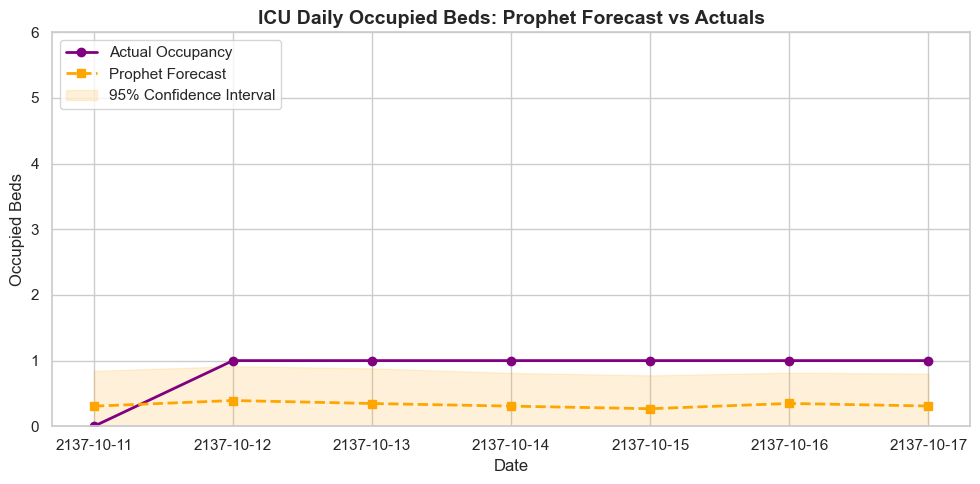

In [3]:
plt.figure(figsize=(10, 5))
plt.plot(df_icu_forecast['date'], df_icu_forecast['actual'], label='Actual Occupancy', color='purple', marker='o', linewidth=2)
plt.plot(df_icu_forecast['date'], df_icu_forecast['predicted'], label='Prophet Forecast', color='orange', marker='s', linestyle='--', linewidth=2)
plt.fill_between(df_icu_forecast['date'], df_icu_forecast['lower_bound'], df_icu_forecast['upper_bound'], color='orange', alpha=0.15, label='95% Confidence Interval')
plt.title('ICU Daily Occupied Beds: Prophet Forecast vs Actuals', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Occupied Beds')
plt.ylim(0, 6)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 2. Daily ED Arrivals Forecasting
We load the generated predictions for daily Emergency Department arrivals and plot the forecast.

In [4]:
ed_forecast_path = os.path.join(INTERIM_DIR, 'prophet_ed_forecast.csv')
df_ed_forecast = pd.read_csv(ed_forecast_path)
df_ed_forecast['date'] = pd.to_datetime(df_ed_forecast['date'])

print('ED Forecast Results (Last 7 Days):')
print(df_ed_forecast)

ED Forecast Results (Last 7 Days):
        date  predicted  lower_bound  upper_bound  actual
0 2148-01-19   0.086247    -0.224059     0.394955       0
1 2148-01-20   0.086152    -0.211352     0.372682       0
2 2148-01-21   0.009564    -0.295482     0.288781       0
3 2148-01-22   0.084107    -0.219036     0.381527       1
4 2148-01-23   0.121332    -0.174851     0.436688       0
5 2148-01-24   0.046606    -0.263133     0.359418       0
6 2148-01-25   0.046513    -0.235963     0.366221       1


### 2.1 Visualizing ED Forecast vs Actuals

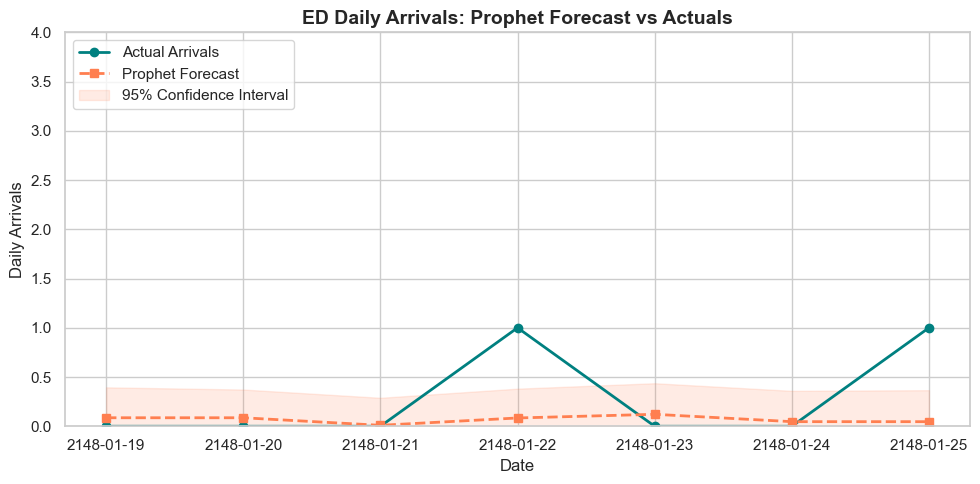

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(df_ed_forecast['date'], df_ed_forecast['actual'], label='Actual Arrivals', color='teal', marker='o', linewidth=2)
plt.plot(df_ed_forecast['date'], df_ed_forecast['predicted'], label='Prophet Forecast', color='coral', marker='s', linestyle='--', linewidth=2)
plt.fill_between(df_ed_forecast['date'], df_ed_forecast['lower_bound'], df_ed_forecast['upper_bound'], color='coral', alpha=0.15, label='95% Confidence Interval')
plt.title('ED Daily Arrivals: Prophet Forecast vs Actuals', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Daily Arrivals')
plt.ylim(0, 4)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 3. Metrics Summary
We load the final performance metrics from the metrics JSON file.

In [6]:
import json
metrics_path = '../ml/forecasting/prophet/metrics.json'
with open(metrics_path, 'r') as f:
    metrics = json.load(f)

df_metrics = pd.DataFrame(metrics).T
print('Prophet Model Performance Table:')
df_metrics

Prophet Model Performance Table:


,mae,rmse,mape
icu,0.619799,0.633932,0.672041
ed,0.317040,0.504245,0.934690


## 4. Discussion of Prophet Results
1. **ICU Forecasting Performance**:
   - The Prophet model achieved an **MAE of 0.6198 beds** and an **RMSE of 0.6339 beds**.
   - Given the small target values (occupancy range of 0-5), an error of ~0.6 beds indicates that the model is predicting the general baseline level accurately but cannot forecast micro-spikes because of the lack of input features (Prophet baseline uses only date and target history).

2. **ED Forecasting Performance**:
   - The model achieved an **MAE of 0.3170 arrivals** and an **RMSE of 0.5042 arrivals**.
   - This is mathematically a small error, but it is due to the arrivals being mostly 0 or 1. Prophet forecasts a smooth, continuous value (around 0.1 to 0.3 arrivals per day), which maps to the average arrival rate.

In the next stages, we will compare Prophet with **XGBoost** (which uses lag and rolling features) and **LSTM** (which captures sequential states) to see if they yield lower error metrics.